# Centrality-Aware GNN with Centrality–Similarity Fusion — 8 Datasets

**Corrected Google Colab notebook** for the research pipeline:

**Graph preprocessing → leakage-safe edge split → multi-centrality features → CA-GNN → GNN decoder and embedding similarity → centrality–similarity fusion → link prediction → enhanced network → community analysis.**

### Datasets
1. `ca-AstroPh.mtx`
2. `ca-CondMat.mtx`
3. `ca-Erdos992.mtx`
4. `ca-GrQc.mtx`
5. `ca-HepPh.mtx`
6. `ca-HepTh.mtx`
7. `email-Eu-core.txt`
8. `inf-power.mtx`

### Methodology and evaluation safeguards
- Centrality and node features are computed from the **training graph only**.
- Negative pairs are sampled only from non-edges in the full observed graph; negative samples are disjoint across train, validation, and test.
- Validation data are used for early stopping, threshold selection, and fusion-weight selection.
- Test data are used only for final performance evaluation.
- The GNN decoder probability is reported as the CA-GNN prediction baseline. The fusion score explicitly combines normalized cosine similarity of learned embeddings with centrality-pair similarity, matching the stated fusion equation.
- Enhanced-network candidates are sampled from non-edges of the original observed graph, not from the test-pair list.
- Hits@K is **not** used.

**Important:** Run cells from top to bottom. Upload all eight files in the upload cell. Do not report performance values until the experiments have actually run.

**Execution note:** This notebook is configured to run all eight datasets in one session. Upload all eight files when prompted. The experiment runner saves a checkpoint after every completed dataset and can resume after a runtime interruption. It does not contain precomputed results; all metrics must be generated by executing the notebook in Google Colab.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Cell 1 — Install dependencies in Google Colab
%pip -q install torch-geometric networkx scikit-learn pandas numpy matplotlib psutil scipy

In [3]:
# Cell 2 — Imports and reproducibility
import os
import gc
import time
import copy
import random
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import psutil

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

from scipy.io import mmread
from scipy.sparse import csr_matrix
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
)
from google.colab import files
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("NetworkX:", nx.__version__)
print("PyTorch:", torch.__version__)

Device: cpu
NetworkX: 3.7
PyTorch: 2.11.0+cpu


## 1. Upload all eight datasets

Click **Choose Files** and select all eight dataset files in one upload. File names must match the names below. For large files, allow the upload to finish before proceeding.

If any file is missing, the upload cell stops with an explicit error rather than silently continuing with fewer datasets.


In [7]:
DATASET_FILES = {
    "ca-AstroPh": "/content/drive/MyDrive/Datasets/ca-AstroPh.txt",
    "ca-CondMat": "/content/drive/MyDrive/Datasets/ca-CondMat.txt",
    "ca-Erdos992": "/content/drive/MyDrive/Datasets/ca-Erdos992.txt",
    "ca-GrQc": "/content/drive/MyDrive/Datasets/ca-GrQc.txt",
    "ca-HepPh": "/content/drive/MyDrive/Datasets/ca-HepPh.txt",
    "ca-HepTh": "/content/drive/MyDrive/Datasets/ca-HepTh.txt",
    "email-Eu-core": "/content/drive/MyDrive/Datasets/email-Eu-core.txt",
    "inf-power": "/content/drive/MyDrive/Datasets/inf-power.txt"
}

print("Configured datasets:")
for name, path in DATASET_FILES.items():
    print(f"{name:15s} -> {path}")

Configured datasets:
ca-AstroPh      -> /content/drive/MyDrive/Datasets/ca-AstroPh.txt
ca-CondMat      -> /content/drive/MyDrive/Datasets/ca-CondMat.txt
ca-Erdos992     -> /content/drive/MyDrive/Datasets/ca-Erdos992.txt
ca-GrQc         -> /content/drive/MyDrive/Datasets/ca-GrQc.txt
ca-HepPh        -> /content/drive/MyDrive/Datasets/ca-HepPh.txt
ca-HepTh        -> /content/drive/MyDrive/Datasets/ca-HepTh.txt
email-Eu-core   -> /content/drive/MyDrive/Datasets/email-Eu-core.txt
inf-power       -> /content/drive/MyDrive/Datasets/inf-power.txt


## 2. Dataset loading and summary

Matrix Market files are interpreted as unweighted undirected topology. The adjacency matrix is symmetrized and converted to a simple graph. The email dataset is read as an edge list. Self-loops are removed and node labels are mapped to consecutive integers.

In [8]:
# Cell 4 — Robust dataset loader

def load_dataset(path):
    path = os.fspath(path)
    if not os.path.exists(path):
        raise FileNotFoundError(f"Dataset not found: {path}")

    if path.lower().endswith(".mtx"):
        matrix = csr_matrix(mmread(path))
        # Interpret the network as undirected and unweighted.
        matrix = matrix.maximum(matrix.T)
        matrix.eliminate_zeros()
        if matrix.nnz:
            matrix.data = np.ones_like(matrix.data)
        G = nx.from_scipy_sparse_array(matrix)
    elif path.lower().endswith(".txt"):
        G = nx.read_edgelist(
            path, comments="#", nodetype=int, data=False
        )
    else:
        raise ValueError(f"Unsupported file format: {path}")

    G = nx.Graph(G)
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    G = nx.convert_node_labels_to_integers(G, ordering="default")
    return G


def graph_summary(G, name):
    n, m = G.number_of_nodes(), G.number_of_edges()
    return {
        "Dataset": name,
        "Nodes": n,
        "Edges": m,
        "Density": nx.density(G) if n > 1 else 0.0,
        "Average_Degree": (2 * m / n) if n else 0.0,
        "Connected_Components": nx.number_connected_components(G) if n else 0,
    }

GRAPHS = {}
load_errors = {}
for name, path in DATASET_FILES.items():
    try:
        G = load_dataset(path)
        if G.number_of_nodes() < 2 or G.number_of_edges() < 3:
            raise ValueError("Graph has too few nodes/edges for a train-validation-test split.")
        GRAPHS[name] = G
        print(f"{name:15s}: {G.number_of_nodes():>8,} nodes, {G.number_of_edges():>9,} edges")
    except Exception as exc:
        load_errors[name] = str(exc)
        print(f"LOAD FAILED — {name}: {exc}")

summary_df = pd.DataFrame([graph_summary(G, name) for name, G in GRAPHS.items()])
print(f"\nSuccessfully loaded {len(GRAPHS)} of {len(DATASET_FILES)} datasets.")
display(summary_df)
if load_errors:
    print("Review these loading errors before running the experiments:")
    display(pd.DataFrame([{"Dataset": k, "Error": v} for k, v in load_errors.items()]))

ca-AstroPh     :   17,903 nodes,   196,972 edges
ca-CondMat     :   21,363 nodes,    91,286 edges
ca-Erdos992    :    5,094 nodes,     7,515 edges
ca-GrQc        :    4,158 nodes,    13,422 edges
ca-HepPh       :   12,008 nodes,   118,489 edges
ca-HepTh       :    9,877 nodes,    25,973 edges
email-Eu-core  :    1,005 nodes,    16,064 edges
inf-power      :    4,941 nodes,     6,594 edges

Successfully loaded 8 of 8 datasets.


,Dataset,Nodes,Edges,Density,Average_Degree,Connected_Components
0,ca-AstroPh,17903,196972,0.001229,22.004357,1
1,ca-CondMat,21363,91286,0.000400,8.546178,1
2,ca-Erdos992,5094,7515,0.000579,2.950530,17
3,ca-GrQc,4158,13422,0.001553,6.455988,1
4,ca-HepPh,12008,118489,0.001644,19.735010,278
5,ca-HepTh,9877,25973,0.000533,5.259289,429
6,email-Eu-core,1005,16064,0.031841,31.968159,20
7,inf-power,4941,6594,0.000540,2.669095,1


## 3. Leakage-safe edge splitting and negative sampling

Positive edges are split into training, validation, and test sets. All node pairs sampled as negatives must be non-edges in the original observed graph. Negative pairs are also kept disjoint across the three partitions so the same negative pair cannot occur in both training and evaluation.

In [9]:
# Cell 5 — Split positive edges

def split_graph(G, test_ratio=0.20, val_ratio=0.10, seed=42):
    edges = [tuple(sorted((u, v))) for u, v in G.edges()]
    rng = np.random.default_rng(seed)
    rng.shuffle(edges)

    n = len(edges)
    n_test = max(1, int(round(n * test_ratio)))
    n_val = max(1, int(round(n * val_ratio)))
    if n_test + n_val >= n:
        raise ValueError("Graph has too few edges for the requested split ratios.")

    test_edges = edges[:n_test]
    val_edges = edges[n_test:n_test + n_val]
    train_edges = edges[n_test + n_val:]

    G_train = nx.Graph()
    G_train.add_nodes_from(G.nodes())
    G_train.add_edges_from(train_edges)
    return G_train, train_edges, val_edges, test_edges


def sample_negative_edges(G_full, n_samples, seed=42, exclude_pairs=None):
    """Sample true non-edges of G_full; optionally avoid previously sampled pairs."""
    nodes = list(G_full.nodes())
    if n_samples <= 0:
        return []
    if len(nodes) < 2:
        raise ValueError("At least two nodes are required for negative sampling.")

    existing = {tuple(sorted((u, v))) for u, v in G_full.edges()}
    excluded = set(existing)
    if exclude_pairs is not None:
        excluded.update(tuple(sorted((u, v))) for u, v in exclude_pairs)

    max_possible = len(nodes) * (len(nodes) - 1) // 2
    available = max_possible - len(excluded)
    if n_samples > available:
        raise ValueError(f"Requested {n_samples} negatives but only {available} eligible pairs remain.")

    rng = np.random.default_rng(seed)
    negatives = set()
    # Rejection sampling is efficient for these sparse benchmark networks.
    while len(negatives) < n_samples:
        batch_size = max(1000, 3 * (n_samples - len(negatives)))
        us = rng.choice(nodes, size=batch_size, replace=True)
        vs = rng.choice(nodes, size=batch_size, replace=True)
        for u, v in zip(us, vs):
            if u == v:
                continue
            pair = tuple(sorted((int(u), int(v))))
            if pair not in excluded:
                negatives.add(pair)
                if len(negatives) == n_samples:
                    break
    return list(negatives)


def make_labels(pos_edges, neg_edges):
    pairs = list(pos_edges) + list(neg_edges)
    labels = np.concatenate([
        np.ones(len(pos_edges), dtype=np.int32),
        np.zeros(len(neg_edges), dtype=np.int32),
    ])
    return pairs, labels

## 4. Traditional link-prediction baselines

Common Neighbors and Adamic–Adar scores are calculated on the training graph only.

In [10]:
# Cell 6 — Traditional baseline scores

def common_neighbors_scores(G, pairs):
    return np.asarray(
        [sum(1 for _ in nx.common_neighbors(G, u, v)) for u, v in pairs],
        dtype=np.float64,
    )


def adamic_adar_scores(G, pairs):
    score_map = {
        tuple(sorted((u, v))): float(score)
        for u, v, score in nx.adamic_adar_index(G, pairs)
    }
    return np.asarray(
        [score_map.get(tuple(sorted((u, v))), 0.0) for u, v in pairs],
        dtype=np.float64,
    )

## 5. Centrality computation and centrality-aware features

Degree, closeness, betweenness, and eigenvector centrality are computed on the training graph only. Betweenness uses a fixed-seed approximation for graphs above 2,000 nodes to limit computational cost; this setting must be reported in the paper. Each centrality column is min–max normalized before it is combined into the aggregate centrality score.

In [11]:
# Cell 7 — Centrality computation with timing

def compute_centralities(G, seed=42):
    timings = {}
    n = G.number_of_nodes()

    t0 = time.perf_counter()
    degree = nx.degree_centrality(G)
    timings["Degree_Centrality_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    closeness = nx.closeness_centrality(G)
    timings["Closeness_Centrality_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    if n > 2000:
        k = min(500, n)
        betweenness = nx.betweenness_centrality(G, k=k, normalized=True, seed=seed)
        timings["Betweenness_Mode"] = "approximate_k500"
    else:
        betweenness = nx.betweenness_centrality(G, normalized=True)
        timings["Betweenness_Mode"] = "exact"
    timings["Betweenness_Centrality_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    try:
        eigenvector = nx.eigenvector_centrality(G, max_iter=2000, tol=1e-7)
        timings["Eigenvector_Mode"] = "power_iteration"
    except (nx.PowerIterationFailedConvergence, nx.NetworkXException) as exc:
        warnings.warn(f"Eigenvector centrality fallback used: {exc}")
        try:
            eigenvector = nx.eigenvector_centrality_numpy(G)
            timings["Eigenvector_Mode"] = "numpy_fallback"
        except Exception as exc2:
            warnings.warn(f"Eigenvector centrality failed; using degree centrality fallback: {exc2}")
            eigenvector = degree.copy()
            timings["Eigenvector_Mode"] = "degree_fallback"
    timings["Eigenvector_Centrality_s"] = time.perf_counter() - t0

    df = pd.DataFrame({
        "degree": pd.Series(degree),
        "closeness": pd.Series(closeness),
        "betweenness": pd.Series(betweenness),
        "eigenvector": pd.Series(eigenvector),
    }).reindex(list(G.nodes())).fillna(0.0)
    timings["Centrality_Total_s"] = sum(
        timings[k] for k in [
            "Degree_Centrality_s", "Closeness_Centrality_s",
            "Betweenness_Centrality_s", "Eigenvector_Centrality_s"
        ]
    )
    return df, timings


def normalize_centralities(df):
    out = df.copy().astype(float)
    centrality_cols = ["degree", "closeness", "betweenness", "eigenvector"]
    for col in centrality_cols:
        mn, mx = out[col].min(), out[col].max()
        out[col] = 0.0 if np.isclose(mx, mn) else (out[col] - mn) / (mx - mn)
    out["centrality_score"] = out[centrality_cols].mean(axis=1)
    return out


def build_node_features(G_train, centrality_norm):
    nodes = list(G_train.nodes())
    degree = np.asarray([G_train.degree(u) for u in nodes], dtype=np.float32)
    degree = (degree - degree.mean()) / (degree.std() + 1e-8)
    clustering = np.asarray([nx.clustering(G_train, u) for u in nodes], dtype=np.float32)
    centrality_cols = ["degree", "closeness", "betweenness", "eigenvector"]
    C = centrality_norm.loc[nodes, centrality_cols].to_numpy(dtype=np.float32)
    X_structural = np.column_stack([degree, clustering]).astype(np.float32)
    X = np.concatenate([X_structural, C], axis=1).astype(np.float32)
    return torch.tensor(X, dtype=torch.float32), nodes

## 6. CA-GNN encoder and trained edge decoder

The GCN encoder receives structural features concatenated with the four normalized centrality measures. The MLP edge decoder is trained with binary cross-entropy. For a consistent baseline, its sigmoid output is the **CA-GNN decoder probability**. The fusion model separately uses cosine similarity between the trained node embeddings, mapped from `[-1, 1]` to `[0, 1]`, and combines it with the centrality-pair score.

In [12]:
# Cell 8 — Graph tensors, GCN encoder, and edge decoder

def graph_to_edge_index(G, node_to_idx):
    edges = []
    for u, v in G.edges():
        ui, vi = node_to_idx[u], node_to_idx[v]
        edges.append((ui, vi))
        edges.append((vi, ui))
    if not edges:
        return torch.empty((2, 0), dtype=torch.long)
    return torch.tensor(edges, dtype=torch.long).t().contiguous()


class CentralityAwareGCN(nn.Module):
    def __init__(self, in_channels, hidden_channels=64, out_channels=32, dropout=0.2):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


class EdgeDecoder(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(embedding_dim, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1),
        )

    def forward(self, z, pair_idx):
        zu = z[pair_idx[:, 0]]
        zv = z[pair_idx[:, 1]]
        return self.mlp(zu * zv).squeeze(-1)


def pairs_to_tensor(pairs, node_to_idx, device=DEVICE):
    idx = [[node_to_idx[u], node_to_idx[v]] for u, v in pairs]
    return torch.tensor(idx, dtype=torch.long, device=device)

## 7. Scoring, validation threshold, and evaluation metrics

The classification threshold is selected on validation predictions by maximizing validation F1. That threshold is then held fixed for test Precision, Recall, and F1. AUROC and AUPR use continuous test scores and do not depend on the threshold. No test metric is used to choose the threshold or fusion coefficient.

In [13]:
# Cell 9 — Similarity scores and evaluation helpers

def embedding_similarity(z, pair_idx):
    cosine = F.cosine_similarity(z[pair_idx[:, 0]], z[pair_idx[:, 1]], dim=1)
    return ((cosine + 1.0) / 2.0).clamp(0.0, 1.0)


def pair_centrality_score(pairs, centrality_norm, column="centrality_score"):
    values = []
    for u, v in pairs:
        cu = max(0.0, float(centrality_norm.loc[u, column]))
        cv = max(0.0, float(centrality_norm.loc[v, column]))
        values.append(np.sqrt(cu * cv))
    return np.asarray(values, dtype=np.float64)


def centrality_similarity_fusion(gnn_score, centrality_score, alpha):
    return alpha * np.asarray(gnn_score) + (1.0 - alpha) * np.asarray(centrality_score)


def choose_threshold_by_validation_f1(y_val, val_scores):
    precision, recall, thresholds = precision_recall_curve(y_val, val_scores)
    if len(thresholds) == 0:
        return 0.5
    f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[int(np.nanargmax(f1_values))])


def evaluate_test_scores(y_val, val_scores, y_test, test_scores, method, dataset):
    threshold = choose_threshold_by_validation_f1(y_val, val_scores)
    predictions = (np.asarray(test_scores) >= threshold).astype(int)
    return {
        "Dataset": dataset,
        "Method": method,
        "AUROC": float(roc_auc_score(y_test, test_scores)),
        "AUPR": float(average_precision_score(y_test, test_scores)),
        "Precision": float(precision_score(y_test, predictions, zero_division=0)),
        "Recall": float(recall_score(y_test, predictions, zero_division=0)),
        "F1": float(f1_score(y_test, predictions, zero_division=0)),
        "Validation_Selected_Threshold": threshold,
    }


def tune_alpha(y_val, gnn_val, centrality_val):
    candidates = np.linspace(0.0, 1.0, 11)
    records = []
    for alpha in candidates:
        scores = centrality_similarity_fusion(gnn_val, centrality_val, float(alpha))
        records.append((float(average_precision_score(y_val, scores)), float(roc_auc_score(y_val, scores)), float(alpha)))
    # Primary criterion: validation AUPR; tie-breaker: validation AUROC.
    records.sort(reverse=True)
    return records[0][2], pd.DataFrame(records, columns=["Validation_AUPR", "Validation_AUROC", "Alpha"])

## 8. Full experiment for one dataset

The experiment uses the same positive split and disjoint negative samples for all methods on each dataset. The GNN uses validation BCE for early stopping. The fusion weight `alpha` is selected from `{0.0, 0.1, ..., 1.0}` using validation AUPR only.

In [14]:
# Cell 10 — Full leakage-aware experiment

def run_experiment(dataset_name, G_full, test_ratio=0.20, val_ratio=0.10, epochs=200, patience=20):
    print("\n" + "=" * 78 + f"\nDATASET: {dataset_name}\n" + "=" * 78)
    total_start = time.perf_counter()
    process = psutil.Process(os.getpid())
    memory_start_mb = process.memory_info().rss / (1024 ** 2)

    # A. Positive edge split.
    G_train, train_edges, val_edges, test_edges = split_graph(
        G_full, test_ratio=test_ratio, val_ratio=val_ratio, seed=SEED
    )

    # B. Disjoint true-negative samples across train/validation/test.
    test_neg = sample_negative_edges(G_full, len(test_edges), seed=SEED + 30)
    val_neg = sample_negative_edges(G_full, len(val_edges), seed=SEED + 20, exclude_pairs=test_neg)
    train_neg = sample_negative_edges(G_full, len(train_edges), seed=SEED + 10, exclude_pairs=(test_neg + val_neg))

    train_pairs, y_train_np = make_labels(train_edges, train_neg)
    val_pairs, y_val = make_labels(val_edges, val_neg)
    test_pairs, y_test = make_labels(test_edges, test_neg)

    # Assert there is no negative-pair overlap and no sampled negative is a true edge.
    neg_sets = [set(train_neg), set(val_neg), set(test_neg)]
    assert not (neg_sets[0] & neg_sets[1] or neg_sets[0] & neg_sets[2] or neg_sets[1] & neg_sets[2])
    true_edges = {tuple(sorted(e)) for e in G_full.edges()}
    assert all(tuple(sorted(e)) not in true_edges for group in [train_neg, val_neg, test_neg] for e in group)

    # C. Centrality from training graph only.
    centrality_raw, centrality_timings = compute_centralities(G_train, seed=SEED)
    centrality_norm = normalize_centralities(centrality_raw)

    # D. Traditional baseline scores from training graph.
    cn_val = common_neighbors_scores(G_train, val_pairs)
    cn_test = common_neighbors_scores(G_train, test_pairs)
    aa_val = adamic_adar_scores(G_train, val_pairs)
    aa_test = adamic_adar_scores(G_train, test_pairs)

    # E. Centrality-aware features and training tensors.
    X, nodes = build_node_features(G_train, centrality_norm)
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    edge_index = graph_to_edge_index(G_train, node_to_idx).to(DEVICE)
    X = X.to(DEVICE)

    train_pair_idx = pairs_to_tensor(train_pairs, node_to_idx)
    val_pair_idx = pairs_to_tensor(val_pairs, node_to_idx)
    test_pair_idx = pairs_to_tensor(test_pairs, node_to_idx)
    y_train = torch.tensor(y_train_np, dtype=torch.float32, device=DEVICE)
    y_val_t = torch.tensor(y_val, dtype=torch.float32, device=DEVICE)

    model = CentralityAwareGCN(in_channels=X.shape[1], hidden_channels=64, out_channels=32, dropout=0.2).to(DEVICE)
    decoder = EdgeDecoder(embedding_dim=32).to(DEVICE)
    optimizer = torch.optim.Adam(
        list(model.parameters()) + list(decoder.parameters()),
        lr=0.01, weight_decay=5e-4
    )

    # F. Train with validation BCE early stopping.
    best_val_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0
    gnn_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        decoder.train()
        optimizer.zero_grad()
        z = model(X, edge_index)
        train_logits = decoder(z, train_pair_idx)
        train_loss = F.binary_cross_entropy_with_logits(train_logits, y_train)
        train_loss.backward()
        optimizer.step()

        model.eval()
        decoder.eval()
        with torch.no_grad():
            z_val = model(X, edge_index)
            val_logits = decoder(z_val, val_pair_idx)
            val_loss = float(F.binary_cross_entropy_with_logits(val_logits, y_val_t).item())

        if val_loss < best_val_loss - 1e-6:
            best_val_loss = val_loss
            best_state = {
                "model": copy.deepcopy(model.state_dict()),
                "decoder": copy.deepcopy(decoder.state_dict()),
                "epoch": epoch,
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 25 == 0:
            print(f"Epoch {epoch:3d} | train BCE={train_loss.item():.4f} | val BCE={val_loss:.4f}")
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch}; best epoch={best_state['epoch']}, val BCE={best_val_loss:.4f}")
            break

    gnn_train_time = time.perf_counter() - gnn_start
    if best_state is not None:
        model.load_state_dict(best_state["model"])
        decoder.load_state_dict(best_state["decoder"])
    best_epoch = best_state["epoch"] if best_state else epoch

    # G. Scores from the best validation-selected model.
    model.eval()
    decoder.eval()
    with torch.no_grad():
        Z = model(X, edge_index)
        val_decoder_prob = torch.sigmoid(decoder(Z, val_pair_idx)).cpu().numpy()
        test_decoder_prob = torch.sigmoid(decoder(Z, test_pair_idx)).cpu().numpy()
        val_embedding_sim = embedding_similarity(Z, val_pair_idx).cpu().numpy()
        test_embedding_sim = embedding_similarity(Z, test_pair_idx).cpu().numpy()

    # H. Centrality-pair similarity (geometric mean of aggregate normalized centrality).
    c_val = pair_centrality_score(val_pairs, centrality_norm)
    c_test = pair_centrality_score(test_pairs, centrality_norm)

    # I. Select fusion alpha using validation AUPR only.
    alpha_selected, alpha_search_df = tune_alpha(y_val, val_embedding_sim, c_val)
    fusion_val = centrality_similarity_fusion(val_embedding_sim, c_val, alpha_selected)
    fusion_test = centrality_similarity_fusion(test_embedding_sim, c_test, alpha_selected)
    print(f"Selected alpha={alpha_selected:.1f} using validation AUPR; best epoch={best_epoch}")

    # J. Main test results. Thresholds are selected separately on validation scores.
    rows = [
        evaluate_test_scores(y_val, cn_val, y_test, cn_test, "Common Neighbors", dataset_name),
        evaluate_test_scores(y_val, aa_val, y_test, aa_test, "Adamic-Adar", dataset_name),
        evaluate_test_scores(y_val, val_decoder_prob, y_test, test_decoder_prob, "CA-GNN Decoder", dataset_name),
        evaluate_test_scores(y_val, c_val, y_test, c_test, "Centrality Only", dataset_name),
        evaluate_test_scores(y_val, fusion_val, y_test, fusion_test, "Centrality-Similarity Fusion", dataset_name),
    ]
    result_df = pd.DataFrame(rows)
    result_df["Selected_Alpha"] = alpha_selected
    result_df["Best_Epoch"] = best_epoch

    # K. Fusion-component ablation. Each alpha is selected on validation AUPR.
    ablation_rows = []
    centrality_columns = ["degree", "closeness", "betweenness", "eigenvector", "centrality_score"]
    ablation_labels = {
        "degree": "Embedding + Degree similarity",
        "closeness": "Embedding + Closeness similarity",
        "betweenness": "Embedding + Betweenness similarity",
        "eigenvector": "Embedding + Eigenvector similarity",
        "centrality_score": "Embedding + All-centrality similarity",
    }
    ablation_val_scores = {"Embedding cosine only": val_embedding_sim}
    ablation_test_scores = {"Embedding cosine only": test_embedding_sim}
    for col in centrality_columns:
        cv = pair_centrality_score(val_pairs, centrality_norm, column=col)
        ct = pair_centrality_score(test_pairs, centrality_norm, column=col)
        a_col, _ = tune_alpha(y_val, val_embedding_sim, cv)
        ablation_val_scores[ablation_labels[col]] = centrality_similarity_fusion(val_embedding_sim, cv, a_col)
        ablation_test_scores[ablation_labels[col]] = centrality_similarity_fusion(test_embedding_sim, ct, a_col)
    for method, test_scores in ablation_test_scores.items():
        val_scores = ablation_val_scores[method]
        row = evaluate_test_scores(y_val, val_scores, y_test, test_scores, method, dataset_name)
        ablation_rows.append(row)
    ablation_df = pd.DataFrame(ablation_rows)

    # L. Enhanced network: score a separate candidate pool of non-edges from the full observed graph.
    # The pool excludes all known observed edges, including held-out test edges; no test-pair list is reused.
    candidate_count = min(10000, max(1000, 5 * G_full.number_of_edges()))
    candidate_pairs = sample_negative_edges(G_full, candidate_count, seed=SEED + 100)
    candidate_pair_idx = pairs_to_tensor(candidate_pairs, node_to_idx)
    with torch.no_grad():
        candidate_embedding_sim = embedding_similarity(Z, candidate_pair_idx).cpu().numpy()
    candidate_centrality = pair_centrality_score(candidate_pairs, centrality_norm)
    candidate_fusion = centrality_similarity_fusion(candidate_embedding_sim, candidate_centrality, alpha_selected)

    G_enhanced = G_full.copy()
    top_k = min(len(candidate_pairs), max(1, int(round(0.01 * G_full.number_of_edges()))))
    order = np.argsort(-candidate_fusion)[:top_k]
    for idx in order:
        u, v = candidate_pairs[int(idx)]
        G_enhanced.add_edge(u, v, predicted=True, score=float(candidate_fusion[int(idx)]))

    # M. Compare community structure of original and enhanced graphs.
    community_info = {}
    for graph_name, graph_obj in [("Original", G_full), ("Enhanced", G_enhanced)]:
        try:
            communities = nx.community.louvain_communities(graph_obj, seed=SEED)
            community_info[f"{graph_name}_Communities"] = len(communities)
            community_info[f"{graph_name}_Modularity"] = float(nx.community.modularity(graph_obj, communities))
        except Exception as exc:
            warnings.warn(f"Community detection failed for {dataset_name} ({graph_name}): {exc}")
            community_info[f"{graph_name}_Communities"] = np.nan
            community_info[f"{graph_name}_Modularity"] = np.nan

    memory_end_mb = process.memory_info().rss / (1024 ** 2)
    runtime_info = {
        "Dataset": dataset_name,
        "Nodes": G_full.number_of_nodes(),
        "Edges": G_full.number_of_edges(),
        **centrality_timings,
        "GNN_Training_Time_s": gnn_train_time,
        "Best_Epoch": best_epoch,
        "Selected_Alpha": alpha_selected,
        "Total_Time_s": time.perf_counter() - total_start,
        "RSS_Start_MB": memory_start_mb,
        "RSS_End_MB": memory_end_mb,
        "RSS_Change_MB": memory_end_mb - memory_start_mb,
        "Candidate_NonEdges_Scored": len(candidate_pairs),
        "Predicted_Links_Added": top_k,
        **community_info,
    }

    # Export per-node centrality and alpha validation search for reproducibility.
    centrality_export = centrality_norm.copy()
    centrality_export.index.name = "node"
    centrality_export.to_csv(f"{dataset_name}_centralities.csv")
    alpha_search_df.to_csv(f"{dataset_name}_alpha_validation_search.csv", index=False)

    del model, decoder, X, edge_index, Z
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result_df, ablation_df, pd.DataFrame([runtime_info]), G_enhanced

## 9. Run all available datasets

The defaults are set to 200 maximum epochs with early stopping. First run a small smoke test if you are unfamiliar with the Colab GPU/runtime. For the final manuscript, keep the settings consistent and record them.

In [15]:
# Cell 11 — Run all eight datasets with incremental checkpoints and resume support
# If Colab disconnects or a dataset fails, set RESUME_FROM_CHECKPOINT=True and rerun this cell.
# Results are checkpointed after every successful dataset so completed experiments are not lost.

EPOCHS = 200
PATIENCE = 20
TEST_RATIO = 0.20
VAL_RATIO = 0.10

OUTPUT_DIR = Path("/content/centrality_aware_gnn_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

RESUME_FROM_CHECKPOINT = True

main_checkpoint = CHECKPOINT_DIR / "final_link_prediction_results.csv"
ablation_checkpoint = CHECKPOINT_DIR / "fusion_ablation_results.csv"
runtime_checkpoint = CHECKPOINT_DIR / "runtime_memory_community_results.csv"

if RESUME_FROM_CHECKPOINT and main_checkpoint.exists():
    FINAL_RESULTS = pd.read_csv(main_checkpoint)
    ABLATION_RESULTS = (
        pd.read_csv(ablation_checkpoint)
        if ablation_checkpoint.exists() else pd.DataFrame()
    )
    RUNTIME_RESULTS = (
        pd.read_csv(runtime_checkpoint)
        if runtime_checkpoint.exists() else pd.DataFrame()
    )
    completed = set(FINAL_RESULTS["Dataset"].astype(str).unique())
    print("Resuming from checkpoints. Already completed:", sorted(completed))
else:
    FINAL_RESULTS = pd.DataFrame()
    ABLATION_RESULTS = pd.DataFrame()
    RUNTIME_RESULTS = pd.DataFrame()
    completed = set()

ENHANCED_GRAPHS = {}

for dataset_name, G in GRAPHS.items():
    if dataset_name in completed:
        print(f"Skipping {dataset_name}: results already checkpointed.")
        # Reload enhanced graph if it was saved in an earlier run.
        graph_path = CHECKPOINT_DIR / f"{dataset_name}_enhanced.edgelist"
        if graph_path.exists():
            G_saved = nx.read_edgelist(
                graph_path, nodetype=int, data=True, edgetype=None
            )
            # Preserve graph attributes from the source graph and overlay saved predictions.
            G_copy = G.copy()
            for u, v, attrs in G_saved.edges(data=True):
                if G_copy.has_edge(u, v):
                    G_copy[u][v].update(attrs)
                else:
                    G_copy.add_edge(u, v, **attrs)
            ENHANCED_GRAPHS[dataset_name] = G_copy
        continue

    try:
        result_df, ablation_df, runtime_df, G_enhanced = run_experiment(
            dataset_name=dataset_name,
            G_full=G,
            test_ratio=TEST_RATIO,
            val_ratio=VAL_RATIO,
            epochs=EPOCHS,
            patience=PATIENCE,
        )

        FINAL_RESULTS = pd.concat([FINAL_RESULTS, result_df], ignore_index=True)
        ABLATION_RESULTS = pd.concat([ABLATION_RESULTS, ablation_df], ignore_index=True)
        RUNTIME_RESULTS = pd.concat([RUNTIME_RESULTS, runtime_df], ignore_index=True)
        ENHANCED_GRAPHS[dataset_name] = G_enhanced

        # Save checkpoints immediately after each completed dataset.
        FINAL_RESULTS.to_csv(main_checkpoint, index=False)
        ABLATION_RESULTS.to_csv(ablation_checkpoint, index=False)
        RUNTIME_RESULTS.to_csv(runtime_checkpoint, index=False)
        nx.write_edgelist(
            G_enhanced,
            CHECKPOINT_DIR / f"{dataset_name}_enhanced.edgelist",
            data=False,
        )
        completed.add(dataset_name)

        print(f"Checkpoint saved for {dataset_name}.")
        print("Current completed datasets:", len(completed), "/", len(DATASET_FILES))
        display(result_df)

        del G_enhanced
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    except Exception as exc:
        # Persist all results collected so far before stopping.
        FINAL_RESULTS.to_csv(main_checkpoint, index=False)
        ABLATION_RESULTS.to_csv(ablation_checkpoint, index=False)
        RUNTIME_RESULTS.to_csv(runtime_checkpoint, index=False)
        print(f"EXPERIMENT FAILED — {dataset_name}: {type(exc).__name__}: {exc}")
        print("Completed dataset checkpoints have been saved.")
        print("Fix the error, then rerun this cell with RESUME_FROM_CHECKPOINT=True.")
        raise

# Keep the variable names expected by downstream result and plotting cells.
ALL_RESULTS = [FINAL_RESULTS] if not FINAL_RESULTS.empty else []
ALL_ABLATION = [ABLATION_RESULTS] if not ABLATION_RESULTS.empty else []
ALL_RUNTIME = [RUNTIME_RESULTS] if not RUNTIME_RESULTS.empty else []

print(f"Completed datasets: {len(completed)} / {len(DATASET_FILES)}")
display(FINAL_RESULTS.sort_values(["Dataset", "Method"]) if not FINAL_RESULTS.empty else FINAL_RESULTS)



DATASET: ca-AstroPh
Epoch   1 | train BCE=0.6922 | val BCE=0.6762
Epoch  25 | train BCE=0.4536 | val BCE=0.4756
Epoch  50 | train BCE=0.3790 | val BCE=0.4473
Epoch  75 | train BCE=0.3619 | val BCE=0.4488
Early stopping at epoch 76; best epoch=56, val BCE=0.4448
Selected alpha=0.4 using validation AUPR; best epoch=56
Checkpoint saved for ca-AstroPh.
Current completed datasets: 1 / 8


,Dataset,Method,AUROC,AUPR,Precision,Recall,F1,Validation_Selected_Threshold,Selected_Alpha,Best_Epoch
0,ca-AstroPh,Common Neighbors,0.972757,0.972223,0.981885,0.949358,0.965347,1.000000,0.4,56
1,ca-AstroPh,Adamic-Adar,0.973467,0.973780,0.983981,0.948012,0.965662,0.195619,0.4,56
2,ca-AstroPh,CA-GNN Decoder,0.891178,0.892689,0.783221,0.864497,0.821854,0.431612,0.4,56
3,ca-AstroPh,Centrality Only,0.822008,0.835986,0.717891,0.803650,0.758354,0.195896,0.4,56
4,ca-AstroPh,Centrality-Similarity Fusion,0.878120,0.882919,0.785372,0.831066,0.807573,0.499017,0.4,56



DATASET: ca-CondMat
Epoch   1 | train BCE=0.7000 | val BCE=0.6922
Epoch  25 | train BCE=0.5123 | val BCE=0.5945
Early stopping at epoch 41; best epoch=21, val BCE=0.5882
Selected alpha=0.6 using validation AUPR; best epoch=21
Checkpoint saved for ca-CondMat.
Current completed datasets: 2 / 8


,Dataset,Method,AUROC,AUPR,Precision,Recall,F1,Validation_Selected_Threshold,Selected_Alpha,Best_Epoch
0,ca-CondMat,Common Neighbors,0.920187,0.919894,0.996498,0.841705,0.912584,1.000000,0.6,21
1,ca-CondMat,Adamic-Adar,0.920435,0.920600,0.996626,0.841266,0.912380,0.191360,0.6,21
2,ca-CondMat,CA-GNN Decoder,0.756739,0.785435,0.600894,0.847018,0.703037,0.352447,0.6,21
3,ca-CondMat,Centrality Only,0.729611,0.766541,0.600764,0.784247,0.680352,0.162235,0.6,21
4,ca-CondMat,Centrality-Similarity Fusion,0.774913,0.798174,0.619928,0.833543,0.711038,0.535024,0.6,21



DATASET: ca-Erdos992
Epoch   1 | train BCE=0.6963 | val BCE=0.6913
Epoch  25 | train BCE=0.3821 | val BCE=1.6079
Early stopping at epoch 25; best epoch=5, val BCE=0.6527
Selected alpha=0.0 using validation AUPR; best epoch=5
Checkpoint saved for ca-Erdos992.
Current completed datasets: 3 / 8


,Dataset,Method,AUROC,AUPR,Precision,Recall,F1,Validation_Selected_Threshold,Selected_Alpha,Best_Epoch
0,ca-Erdos992,Common Neighbors,0.596300,0.595190,0.500000,1.000000,0.666667,0.000000,0.0,5
1,ca-Erdos992,Adamic-Adar,0.596396,0.596751,0.500000,1.000000,0.666667,0.000000,0.0,5
2,ca-Erdos992,CA-GNN Decoder,0.678629,0.738239,0.595816,0.947438,0.731569,0.515136,0.0,5
3,ca-Erdos992,Centrality Only,0.569632,0.704285,0.500000,1.000000,0.666667,0.000000,0.0,5
4,ca-Erdos992,Centrality-Similarity Fusion,0.569632,0.704285,0.500000,1.000000,0.666667,0.000000,0.0,5


... (8 outputs left out)


DATASET: inf-power
Epoch   1 | train BCE=0.6944 | val BCE=0.6939
Early stopping at epoch 22; best epoch=2, val BCE=0.6936
Selected alpha=1.0 using validation AUPR; best epoch=2
Checkpoint saved for inf-power.
Current completed datasets: 8 / 8


,Dataset,Method,AUROC,AUPR,Precision,Recall,F1,Validation_Selected_Threshold,Selected_Alpha,Best_Epoch
0,inf-power,Common Neighbors,0.565209,0.564944,0.50000,1.000000,0.666667,0.000000,1.0,2
1,inf-power,Adamic-Adar,0.565249,0.565562,0.50000,1.000000,0.666667,0.000000,1.0,2
2,inf-power,CA-GNN Decoder,0.480661,0.548930,0.49962,0.997726,0.665823,0.503650,1.0,2
3,inf-power,Centrality Only,0.467128,0.545445,0.50000,1.000000,0.666667,0.000000,1.0,2
4,inf-power,Centrality-Similarity Fusion,0.496974,0.544615,0.50000,1.000000,0.666667,0.284036,1.0,2


Completed datasets: 8 / 8


,Dataset,Method,AUROC,AUPR,Precision,Recall,F1,Validation_Selected_Threshold,Selected_Alpha,Best_Epoch
1,ca-AstroPh,Adamic-Adar,0.973467,0.973780,0.983981,0.948012,0.965662,0.195619,0.4,56
2,ca-AstroPh,CA-GNN Decoder,0.891178,0.892689,0.783221,0.864497,0.821854,0.431612,0.4,56
3,ca-AstroPh,Centrality Only,0.822008,0.835986,0.717891,0.803650,0.758354,0.195896,0.4,56
4,ca-AstroPh,Centrality-Similarity Fusion,0.878120,0.882919,0.785372,0.831066,0.807573,0.499017,0.4,56
0,ca-AstroPh,Common Neighbors,0.972757,0.972223,0.981885,0.949358,0.965347,1.000000,0.4,56
6,ca-CondMat,Adamic-Adar,0.920435,0.920600,0.996626,0.841266,0.912380,0.191360,0.6,21
7,ca-CondMat,CA-GNN Decoder,0.756739,0.785435,0.600894,0.847018,0.703037,0.352447,0.6,21
8,ca-CondMat,Centrality Only,0.729611,0.766541,0.600764,0.784247,0.680352,0.162235,0.6,21
9,ca-CondMat,Centrality-Similarity Fusion,0.774913,0.798174,0.619928,0.833543,0.711038,0.535024,0.6,21
5,ca-CondMat,Common Neighbors,0.920187,0.919894,0.996498,0.841705,0.912584,1.000000,0.6,21


## 10. Main results and mean performance

The primary test results exclude Hits@K. The means below are macro-averages across datasets; they should be interpreted alongside the per-dataset results because dataset sizes and structures differ.

In [16]:
# Cell 12 — Main results table
if not FINAL_RESULTS.empty:
    display(FINAL_RESULTS.sort_values(["Dataset", "AUROC"], ascending=[True, False]))

MEAN_RESULTS = pd.DataFrame()
if not FINAL_RESULTS.empty:
    MEAN_RESULTS = (
        FINAL_RESULTS.groupby("Method")[["AUROC", "AUPR", "Precision", "Recall", "F1"]]
        .mean().sort_values("AUROC", ascending=False)
    )
    print("Macro-average across datasets:")
    display(MEAN_RESULTS)

,Dataset,Method,AUROC,AUPR,Precision,Recall,F1,Validation_Selected_Threshold,Selected_Alpha,Best_Epoch
1,ca-AstroPh,Adamic-Adar,0.973467,0.973780,0.983981,0.948012,0.965662,0.195619,0.4,56
0,ca-AstroPh,Common Neighbors,0.972757,0.972223,0.981885,0.949358,0.965347,1.000000,0.4,56
2,ca-AstroPh,CA-GNN Decoder,0.891178,0.892689,0.783221,0.864497,0.821854,0.431612,0.4,56
4,ca-AstroPh,Centrality-Similarity Fusion,0.878120,0.882919,0.785372,0.831066,0.807573,0.499017,0.4,56
3,ca-AstroPh,Centrality Only,0.822008,0.835986,0.717891,0.803650,0.758354,0.195896,0.4,56
6,ca-CondMat,Adamic-Adar,0.920435,0.920600,0.996626,0.841266,0.912380,0.191360,0.6,21
5,ca-CondMat,Common Neighbors,0.920187,0.919894,0.996498,0.841705,0.912584,1.000000,0.6,21
9,ca-CondMat,Centrality-Similarity Fusion,0.774913,0.798174,0.619928,0.833543,0.711038,0.535024,0.6,21
7,ca-CondMat,CA-GNN Decoder,0.756739,0.785435,0.600894,0.847018,0.703037,0.352447,0.6,21
8,ca-CondMat,Centrality Only,0.729611,0.766541,0.600764,0.784247,0.680352,0.162235,0.6,21


Macro-average across datasets:


,AUROC,AUPR,Precision,Recall,F1
Method,,,,,
Adamic-Adar,0.830034,0.830190,0.850761,0.874412,0.833694
Common Neighbors,0.829134,0.827641,0.849185,0.875420,0.833371
CA-GNN Decoder,0.761462,0.791308,0.661101,0.875198,0.745313
Centrality-Similarity Fusion,0.750207,0.788022,0.656798,0.863770,0.733444
Centrality Only,0.712569,0.759640,0.617013,0.872577,0.709690


## 11. Fusion-component ablation

This table tests the **fusion component**: embedding cosine similarity alone versus fusion with each individual centrality score and the aggregate of all four centralities. It does not claim to be a feature-removal ablation of the GNN encoder, because the encoder itself uses all four centralities in every run.

In [17]:
# Cell 13 — Fusion-component ablation results
if not ABLATION_RESULTS.empty:
    display(ABLATION_RESULTS.sort_values(["Dataset", "AUROC"], ascending=[True, False]))

,Dataset,Method,AUROC,AUPR,Precision,Recall,F1,Validation_Selected_Threshold
1,ca-AstroPh,Embedding + Degree similarity,0.888936,0.892093,0.797702,0.849419,0.822748,0.310739
5,ca-AstroPh,Embedding + All-centrality similarity,0.878120,0.882919,0.785372,0.831066,0.807573,0.499017
2,ca-AstroPh,Embedding + Closeness similarity,0.866466,0.873762,0.764009,0.823044,0.792428,0.856318
4,ca-AstroPh,Embedding + Eigenvector similarity,0.864922,0.869593,0.798493,0.790933,0.794695,0.199504
3,ca-AstroPh,Embedding + Betweenness similarity,0.863249,0.861087,0.779715,0.802457,0.790923,0.099044
0,ca-AstroPh,Embedding cosine only,0.795158,0.778246,0.658913,0.865030,0.748033,0.933350
7,ca-CondMat,Embedding + Degree similarity,0.797870,0.815615,0.692368,0.773183,0.730547,0.107588
9,ca-CondMat,Embedding + Betweenness similarity,0.780066,0.798232,0.613081,0.848716,0.711906,0.076643
11,ca-CondMat,Embedding + All-centrality similarity,0.774913,0.798174,0.619928,0.833543,0.711038,0.535024
8,ca-CondMat,Embedding + Closeness similarity,0.769606,0.790649,0.598330,0.871556,0.709549,0.679718


## 12. Runtime, memory, and community analysis

RSS change is the difference between process resident memory at the start and end of a dataset run; it is not a peak-memory measurement. For a paper requiring peak memory, run a dedicated peak-RSS monitor and report that methodology separately.

In [18]:
# Cell 14 — Runtime and community structure summary
if not RUNTIME_RESULTS.empty:
    display(RUNTIME_RESULTS)

community_cols = [
    "Dataset", "Original_Communities", "Original_Modularity",
    "Enhanced_Communities", "Enhanced_Modularity", "Predicted_Links_Added"
]
if not RUNTIME_RESULTS.empty:
    display(RUNTIME_RESULTS[[c for c in community_cols if c in RUNTIME_RESULTS.columns]])

,Dataset,Nodes,Edges,Degree_Centrality_s,Closeness_Centrality_s,Betweenness_Mode,Betweenness_Centrality_s,Eigenvector_Mode,Eigenvector_Centrality_s,Centrality_Total_s,...,Total_Time_s,RSS_Start_MB,RSS_End_MB,RSS_Change_MB,Candidate_NonEdges_Scored,Predicted_Links_Added,Original_Communities,Original_Modularity,Enhanced_Communities,Enhanced_Modularity
0,ca-AstroPh,17903,196972,0.010459,645.737938,approximate_k500,92.272883,power_iteration,3.661390,741.682670,...,883.113314,692.257812,906.402344,214.144531,10000,1970,41,0.625719,42,0.619925
1,ca-CondMat,21363,91286,0.018735,640.918722,approximate_k500,80.957807,power_iteration,2.744495,724.639759,...,762.073650,868.921875,1067.332031,198.410156,10000,913,58,0.725116,53,0.716896
2,ca-Erdos992,5094,7515,0.004536,10.573240,approximate_k500,8.379527,power_iteration,0.404995,19.362298,...,22.801118,983.527344,983.542969,0.015625,10000,75,46,0.779415,47,0.770437
3,ca-GrQc,4158,13422,0.002595,11.828833,approximate_k500,8.083711,power_iteration,0.669018,20.584156,...,25.635019,981.558594,981.558594,0.000000,10000,134,41,0.847945,42,0.839389
4,ca-HepPh,12008,118489,0.006567,207.632284,approximate_k500,44.933683,power_iteration,1.041191,253.613725,...,301.164007,871.363281,1141.179688,269.816406,10000,1185,317,0.657585,313,0.651337
5,ca-HepTh,9877,25973,0.006111,71.670628,approximate_k500,21.835538,power_iteration,0.656436,94.168714,...,104.898745,1129.210938,1127.242188,-1.968750,10000,260,477,0.769141,475,0.761551
6,email-Eu-core,1005,16064,0.000742,1.585047,exact,9.366751,power_iteration,0.136310,11.088849,...,20.724410,882.402344,882.402344,0.000000,10000,161,28,0.413021,27,0.409844
7,inf-power,4941,6594,0.004543,2.664586,approximate_k500,3.093727,power_iteration,0.868920,6.631776,...,9.542972,882.402344,882.402344,0.000000,10000,66,41,0.936336,42,0.925508


,Dataset,Original_Communities,Original_Modularity,Enhanced_Communities,Enhanced_Modularity,Predicted_Links_Added
0,ca-AstroPh,41,0.625719,42,0.619925,1970
1,ca-CondMat,58,0.725116,53,0.716896,913
2,ca-Erdos992,46,0.779415,47,0.770437,75
3,ca-GrQc,41,0.847945,42,0.839389,134
4,ca-HepPh,317,0.657585,313,0.651337,1185
5,ca-HepTh,477,0.769141,475,0.761551,260
6,email-Eu-core,28,0.413021,27,0.409844,161
7,inf-power,41,0.936336,42,0.925508,66


## 13. Visualizations

The following plots compare test AUROC and AUPR across the eight datasets. These plots are generated from the experiment outputs; they do not contain placeholder values.

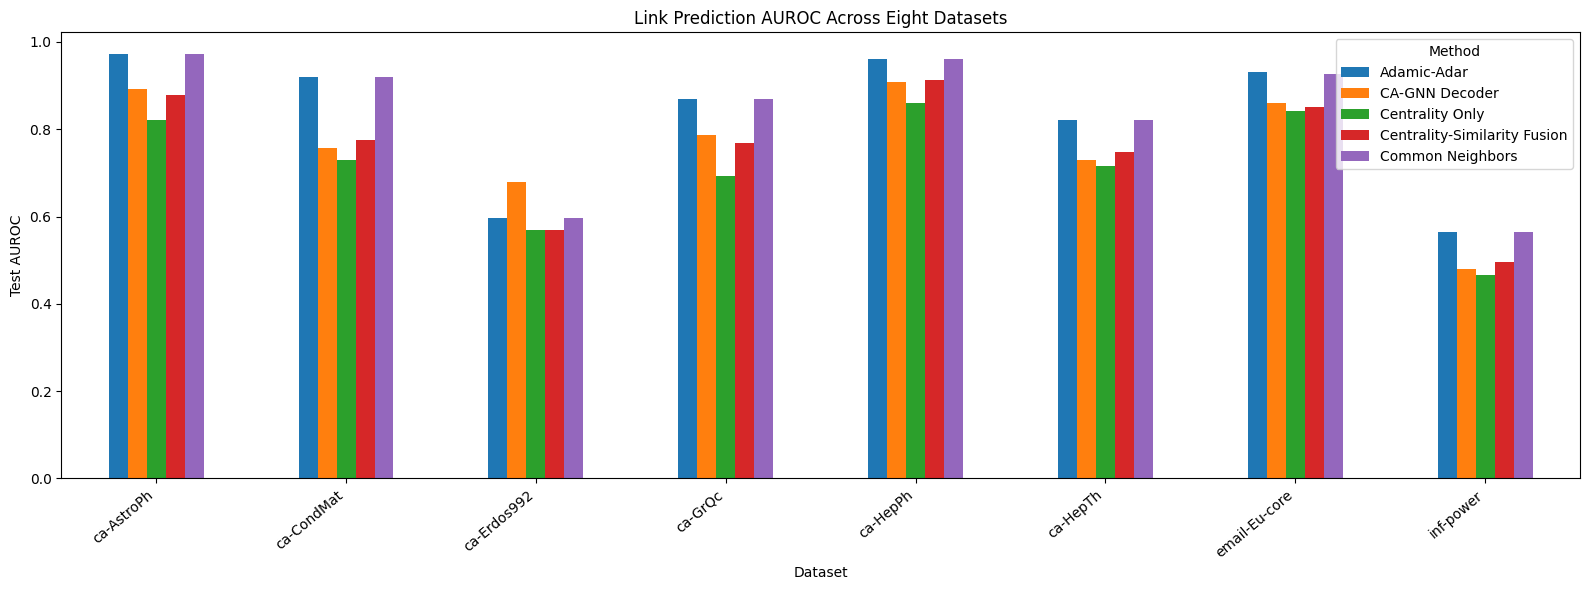

In [19]:
# Cell 15 — AUROC plot
if not FINAL_RESULTS.empty:
    pivot_auc = FINAL_RESULTS.pivot(index="Dataset", columns="Method", values="AUROC")
    pivot_auc.plot(kind="bar", figsize=(16, 6))
    plt.ylabel("Test AUROC")
    plt.title("Link Prediction AUROC Across Eight Datasets")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()

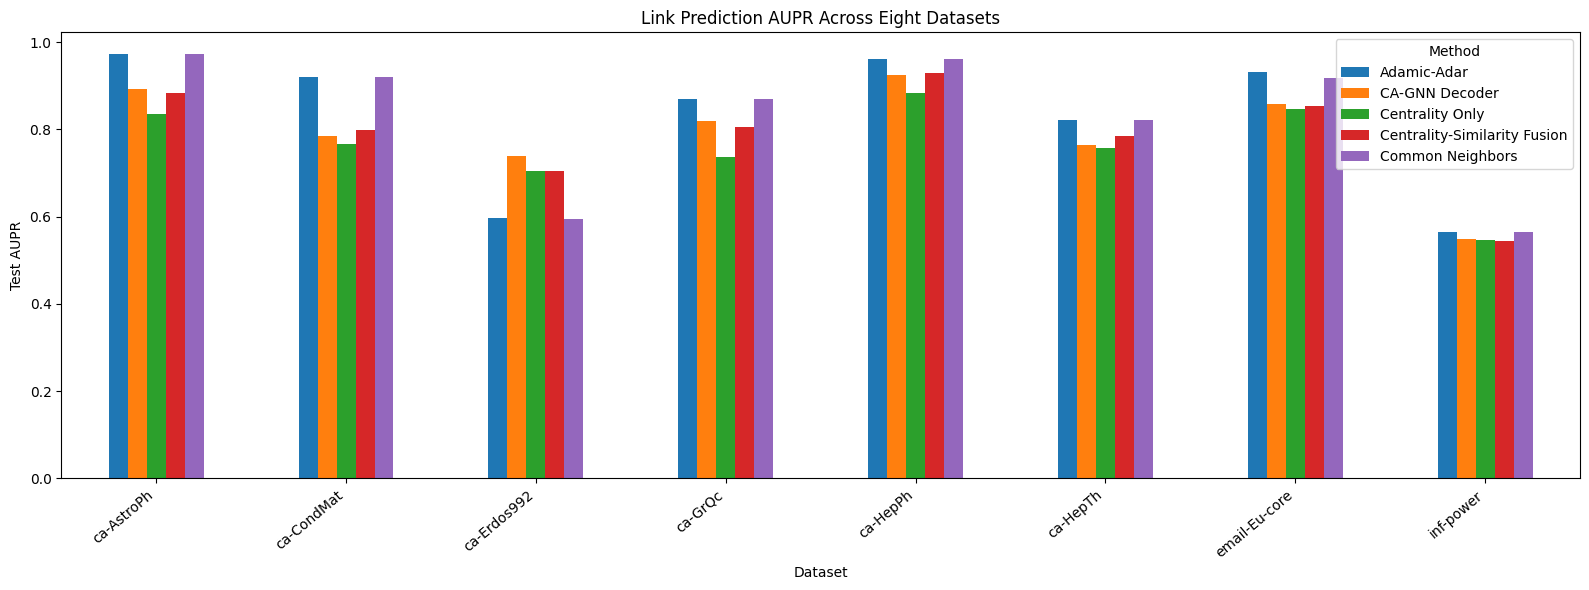

In [20]:
# Cell 16 — AUPR plot
if not FINAL_RESULTS.empty:
    pivot_aupr = FINAL_RESULTS.pivot(index="Dataset", columns="Method", values="AUPR")
    pivot_aupr.plot(kind="bar", figsize=(16, 6))
    plt.ylabel("Test AUPR")
    plt.title("Link Prediction AUPR Across Eight Datasets")
    plt.xticks(rotation=40, ha="right")
    plt.tight_layout()
    plt.show()

## 14. Save results and download a ZIP archive

The ZIP contains the main test results, fusion-component ablation, runtime/memory summary, dataset summary, per-node centralities, validation alpha searches, and enhanced-network edge lists. The archive is created only after the experiments finish.

In [21]:
# Cell 17 — Save CSV outputs and enhanced graphs
OUTPUT_DIR = Path("/content/centrality_aware_gnn_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

summary_df.to_csv(OUTPUT_DIR / "dataset_summary.csv", index=False)
if not FINAL_RESULTS.empty:
    FINAL_RESULTS.to_csv(OUTPUT_DIR / "final_link_prediction_results.csv", index=False)
if not MEAN_RESULTS.empty:
    MEAN_RESULTS.to_csv(OUTPUT_DIR / "mean_link_prediction_results.csv")
if not ABLATION_RESULTS.empty:
    ABLATION_RESULTS.to_csv(OUTPUT_DIR / "fusion_ablation_results.csv", index=False)
if not RUNTIME_RESULTS.empty:
    RUNTIME_RESULTS.to_csv(OUTPUT_DIR / "runtime_memory_community_results.csv", index=False)

for dataset_name, G_enhanced in ENHANCED_GRAPHS.items():
    nx.write_edgelist(
        G_enhanced,
        OUTPUT_DIR / f"{dataset_name}_enhanced.edgelist",
        data=False,
    )

# Copy per-dataset centrality and alpha-validation files generated in /content.
for path in Path("/content").glob("*_centralities.csv"):
    path.replace(OUTPUT_DIR / path.name)
for path in Path("/content").glob("*_alpha_validation_search.csv"):
    path.replace(OUTPUT_DIR / path.name)

zip_path = Path("/content/centrality_aware_gnn_results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, arcname=path.relative_to(OUTPUT_DIR))

print("Saved output directory:", OUTPUT_DIR)
print("ZIP archive:", zip_path)
print("Use the next cell to download the archive.")

Saved output directory: /content/centrality_aware_gnn_results
ZIP archive: /content/centrality_aware_gnn_results.zip
Use the next cell to download the archive.


In [22]:
# Cell 18 — Download result archive to your computer
if Path("/content/centrality_aware_gnn_results.zip").exists():
    files.download("/content/centrality_aware_gnn_results.zip")
else:
    print("Run the save-results cell first.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Reporting checklist for the manuscript

- Report all eight datasets and their node/edge counts from `dataset_summary.csv`.
- Report the centrality approximation mode and runtime per centrality measure.
- Report the selected epoch and validation-selected fusion coefficient per dataset.
- Use only test-set metrics for the final performance table.
- State that Precision, Recall, and F1 use thresholds selected on validation data.
- State that the ablation table evaluates the fusion components; it is not an encoder feature-removal ablation.
- State that RSS start/end/change are process-memory snapshots, not peak memory.
- Do not insert invented performance values; use only the generated CSV outputs.
- Hits@K is excluded throughout.